# Setup

In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gridforecast.config import REPORT_DIR, TEST_START, UK
from gridforecast.data.store import load
from gridforecast.evaluation import metrics
from gridforecast.features.build import FEATURES, TARGET
from gridforecast.models.gbm import DEFAULT_PARAMS
from gridforecast.models.tune import load_best_params
from gridforecast.pipeline.tables import ORIGINS

runs = {
    "LightGBM": pd.read_parquet(REPORT_DIR / "backtests" / "lgbm.parquet"),
    "LightGBM + CQR": pd.read_parquet(REPORT_DIR / "backtests" / "lgbm_cqr.parquet"),
}

c:\PostGrad - ESDA\Personal Projects\gb-grid-forecaster\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Coverage Before and After The Correction

In [2]:
cols = ["coverage_80", "below_q10", "above_q90", "width_80", "pinball"]
pd.DataFrame({name: metrics.score(p) for name, p in runs.items()}).T[cols].round(3)

,coverage_80,below_q10,above_q90,width_80,pinball
LightGBM,0.640,0.164,0.196,2525.886,339.501
LightGBM + CQR,0.793,0.099,0.107,3452.948,329.881


# Coverage by Season

In [3]:
cqr = runs["LightGBM + CQR"]
season = (cqr["target_time"].dt.tz_convert(UK).dt.month % 12 // 3).map(
    {0: "Winter", 1: "Spring", 2: "Summer", 3: "Autumn"}
)
metrics.score_by(cqr, season)[cols].round(3)

,coverage_80,below_q10,above_q90,width_80,pinball
Autumn,0.801,0.057,0.141,3276.162,295.784
Spring,0.731,0.144,0.126,3384.951,383.449
Summer,0.842,0.106,0.051,3605.828,308.678
Winter,0.800,0.089,0.112,3544.978,331.312


# Coverage by Lead Day

In [4]:
metrics.score_by(cqr, "lead_day")[cols].round(3)

,coverage_80,below_q10,above_q90,width_80,pinball
1,0.792,0.099,0.109,3444.611,328.927
2,0.795,0.100,0.106,3461.284,330.834


# Reliability plot

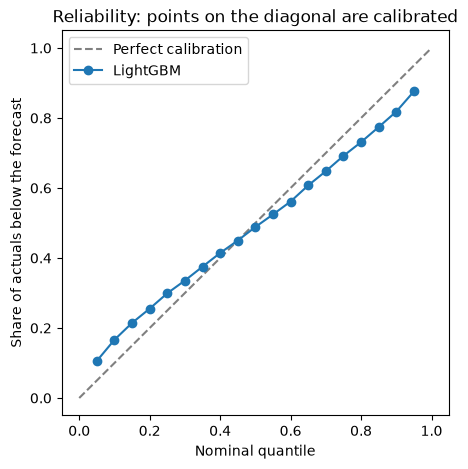

In [5]:
rows = load(ORIGINS)
rows = rows[rows[TARGET].notna()]
cut = pd.Timestamp(TEST_START, tz="UTC")
train, test = rows[rows["target_time"] < cut], rows[rows["issue_time"] >= cut]
params = DEFAULT_PARAMS | load_best_params()
levels = np.round(np.arange(0.05, 1.0, 0.05), 2)
observed = []
for q in levels:
    model = lgb.LGBMRegressor(objective="quantile", alpha=q, n_estimators=600, **params)
    model.fit(train[FEATURES], train[TARGET])
    observed.append(float((test[TARGET] < model.predict(test[FEATURES])).mean()))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], ls="--", color="grey", label="Perfect calibration")
ax.plot(levels, observed, marker="o", label="LightGBM")
ax.set(
    xlabel="Nominal quantile",
    ylabel="Share of actuals below the forecast",
    title="Reliability: points on the diagonal are calibrated",
)
ax.legend()

# Fan Chart for One Week

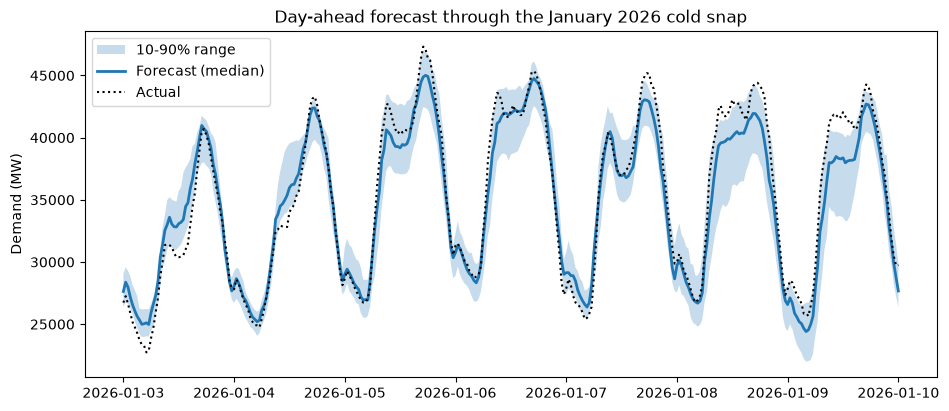

In [6]:
week = cqr[(cqr["lead_day"] == 1)].copy()
week["local"] = week["target_time"].dt.tz_convert(UK).dt.tz_localize(None)
# The January 2026 cold snap: on Mon 5 Jan GB demand hit its highest level since 2018
first_day = pd.Timestamp("2026-01-03")  # Sat 3 Jan to Sat 10 Jan, UK local time
week = week[week["local"].between(first_day, first_day + pd.Timedelta(days=7))]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(week["local"], week["q10"], week["q90"], alpha=0.25, label="10-90% range")
ax.plot(week["local"], week["q50"], lw=2, label="Forecast (median)")
ax.plot(week["local"], week["indo_mw"], color="black", ls=":", label="Actual")
ax.set(ylabel="Demand (MW)", title="Day-ahead forecast through the January 2026 cold snap")
ax.legend()

In [7]:
(REPORT_DIR / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(REPORT_DIR / "figures" / "fan_chart.png", dpi=150, bbox_inches="tight")